## Refining the comparative analysis for the Ross Sea compare manuscript 

I want to create a clean data file with the values we are comparing, and rejig the analysis so that it makes sense. 

We want to find a way to assess correlation that does not break any independence rules and tells us how comparable these different methods are. 

We want to look at: 

- Breeding pairs (midwinter)
- Breeding adults (BP x 2)  
- springtime abundance indices 
- chicks 

In [ ]:
#Importing packages

import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from scipy import stats
from scipy.optimize import minimize
from scipy.stats import chi2
from scipy.stats import pearsonr, spearmanr

from sklearn.metrics import mean_squared_error
from sklearn.utils import resample
from sklearn.preprocessing import StandardScaler
import statsmodels.formula.api as smf

import pymc as pm
import arviz as az



In [2]:
# Loading data 

INPUTPATH = "/mnt/c/Users/rfo37/OneDrive - University of Canterbury/Github/SAR_RossSea_compare/SAR_RossSea_compare/"

df_RossSea = pd.read_csv(os.path.join(INPUTPATH, "Data/RS_pops2425_combined.csv"))


#We attempted to use the Winterl density model on our VHR optical derived areas but this resulted in a large over estimate in colony size due to the estimated rho values so we chose to exclude these data from further analysis
#remove the VHR-rho

#creating categories
df_RossSea = df_RossSea.astype({
    'method': 'category',
    'type': 'category',
    'colony': 'category',
    'year': 'category', 
    'notes': 'category'
})

# Exclude a level from method 
noVHR_rho_df = df_RossSea[df_RossSea["method"] != "VHR-rho"]


In [3]:
#There were also three separate values calculated for Coulman Island 2025, on top of the iceberg, at the colony and combined, we want to exclude the non combined ones for now. 

condition_exclude = (noVHR_rho_df['notes'] == 'colony') | (noVHR_rho_df['notes'] == 'iceberg')

noVHR_rho_df = noVHR_rho_df[#condition_include & 
    ~condition_exclude]

print(noVHR_rho_df)


         colony site_id             type        date  month   day  year  \
0       Crozier    CROZ           adults  21/11/2024   11.0  21.0  2024   
1       Crozier    CROZ           adults  22/11/2025   11.0  22.0  2025   
2       Coulman    COUL           chicks  21/11/2024   11.0  21.0  2024   
3       Coulman    COUL           chicks   6/12/2025   12.0   6.0  2025   
4       Crozier    CROZ           chicks  21/11/2024   11.0  21.0  2024   
..          ...     ...              ...         ...    ...   ...   ...   
141    Franklin    FRAN  abundance index  24/10/2025   10.0  24.0  2025   
142       Roget    ROGE  abundance index  22/10/2025   10.0  22.0  2025   
143       Roget    ROGE  abundance index  11/10/2024   10.0  11.0  2024   
144  Washington    WASH  abundance index  27/10/2024   10.0  27.0  2024   
145  Washington    WASH  abundance index   1/11/2025   11.0   1.0  2025   

       DOY        lat         lon     count     count_se     method  \
0    325.0 -77.452742  169.2

### Now we want to refine the dataset to look at just the datapoints needed for the comparison between methods

In [4]:
# ---------------------------------------------------------
# Chick counts
# ---------------------------------------------------------

chicks = (
    noVHR_rho_df[
        (noVHR_rho_df['method'] == 'chicks') &
        (noVHR_rho_df['year'].isin([2024, 2025]))
    ][
        ['colony', 'year', 'count']
    ]
    .rename(columns={
        'count': 'chick_count'
    })
)

chicks

# ---------------------------------------------------------
# SAR-bp counts
# ---------------------------------------------------------

SAR_bp = (
    noVHR_rho_df[
        (noVHR_rho_df['method'] == 'SAR-bp') &
        (noVHR_rho_df['year'].isin([2024, 2025]))
    ][
        ['colony', 'year', 'count']
    ]
    .rename(columns={
        'count': 'sar-bp_count'
    })
)
SAR_bp


# ---------------------------------------------------------
# VHR-bayes counts
# ---------------------------------------------------------

VHR_bayes = (
    noVHR_rho_df[
        (noVHR_rho_df['method'] == 'VHR-bayes') &
        (noVHR_rho_df['year'].isin([2024, 2025]))
    ][
        ['colony', 'year', 'count']
    ]
    .rename(columns={
        'count': 'vhr-bayes_count'
    })
)
VHR_bayes




,colony,year,vhr-bayes_count
130,Beaufort,2024,293.27000
131,Beaufort,2025,273.90000
132,Colbeck,2024,23821.74000
133,Colbeck,2025,23618.61000
134,Coulman,2025,12409.81000
137,Coulman,2024,12045.81618
138,Crozier,2024,1332.22000
139,Crozier,2025,1715.35000
140,Franklin,2024,3172.53000
141,Franklin,2025,2998.27000


In [5]:
## Now we want to combine them
combined = (
    SAR_bp
    .merge(
        chicks,
        on=['colony', 'year'],
        how='left'
    )
)
combined

,colony,year,sar-bp_count,chick_count
0,Beaufort,2025,563.95,NaN
1,Colbeck,2025,21418.41,NaN
2,Coulman,2025,16088.12,6686.0
3,Coulman,2024,16376.19,21242.0
4,Crozier,2025,1990.66,2782.0
5,Crozier,2024,2349.79,2773.0
6,Franklin,2025,4318.43,NaN
7,Franklin,2024,5029.93,NaN
8,Roget,2025,7252.01,7736.0
9,Roget,2024,5261.45,7397.0


In [8]:
## Now we want to combine them again
combined_2 = (
    combined
    .merge(
        VHR_bayes,
        on=['colony', 'year'],
        how='left'
    )
)
combined_2

combined_2.to_csv(os.path.join(INPUTPATH, "Data/compare_df.csv"), index=False)
print(combined_2)


        colony  year  sar-bp_count  chick_count  vhr-bayes_count
0     Beaufort  2025        563.95          NaN        273.90000
1      Colbeck  2025      21418.41          NaN      23618.61000
2      Coulman  2025      16088.12       6686.0      12409.81000
3      Coulman  2024      16376.19      21242.0      12045.81618
4      Crozier  2025       1990.66       2782.0       1715.35000
5      Crozier  2024       2349.79       2773.0       1332.22000
6     Franklin  2025       4318.43          NaN       2998.27000
7     Franklin  2024       5029.93          NaN       3172.53000
8        Roget  2025       7252.01       7736.0       4049.60000
9        Roget  2024       5261.45       7397.0       4382.11000
10  Washington  2025      11367.90      14297.0       6819.64000
11  Washington  2024      10341.24      13803.0       7458.19000


In [11]:
#Adding new column (breeding adults = bp x 2)
combined_2["breeding_adults"] = combined_2["sar-bp_count"] * 2
print(combined_2)

        colony  year  sar-bp_count  chick_count  vhr-bayes_count  \
0     Beaufort  2025        563.95          NaN        273.90000   
1      Colbeck  2025      21418.41          NaN      23618.61000   
2      Coulman  2025      16088.12       6686.0      12409.81000   
3      Coulman  2024      16376.19      21242.0      12045.81618   
4      Crozier  2025       1990.66       2782.0       1715.35000   
5      Crozier  2024       2349.79       2773.0       1332.22000   
6     Franklin  2025       4318.43          NaN       2998.27000   
7     Franklin  2024       5029.93          NaN       3172.53000   
8        Roget  2025       7252.01       7736.0       4049.60000   
9        Roget  2024       5261.45       7397.0       4382.11000   
10  Washington  2025      11367.90      14297.0       6819.64000   
11  Washington  2024      10341.24      13803.0       7458.19000   

    breeding_adults  
0           1127.90  
1          42836.82  
2          32176.24  
3          32752.38  
4    

### Ok the data is saved, now we move forward using the combined_2 dataset. 

### We want to asess

## We also want to make a simple barplot with all three (four datatypes) different methods 

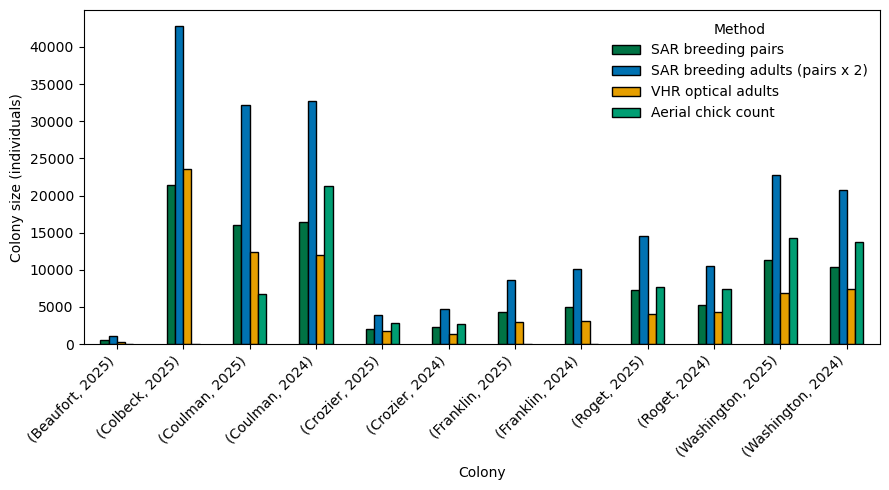

In [17]:
import matplotlib.pyplot as plt

# pick the columns to plot and give them readable legend names
plot_df = combined_2[["colony", "year", "sar-bp_count", "breeding_adults", "vhr-bayes_count", "chick_count"]]
plot_df = plot_df.rename(columns={
    "sar-bp_count": "SAR breeding pairs",
    "breeding_adults": "SAR breeding adults (pairs x 2)",
    "vhr-bayes_count": "VHR optical adults",
    "chick_count": "Aerial chick count",
})

#plot_df = plot_df.join(combined_2["year"])
plot_df = plot_df.set_index(["colony", "year"])

ax = plot_df.plot.bar(color=["#007344", "#0072B2", "#E69F00", "#009E73"],
                      edgecolor="black", figsize=(9, 5))
ax.set_xlabel("Colony")
ax.set_ylabel("Colony size (individuals)")
ax.legend(title="Method", frameon=False)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
#plt.savefig("colony_sizes.png", dpi=300)
plt.show()

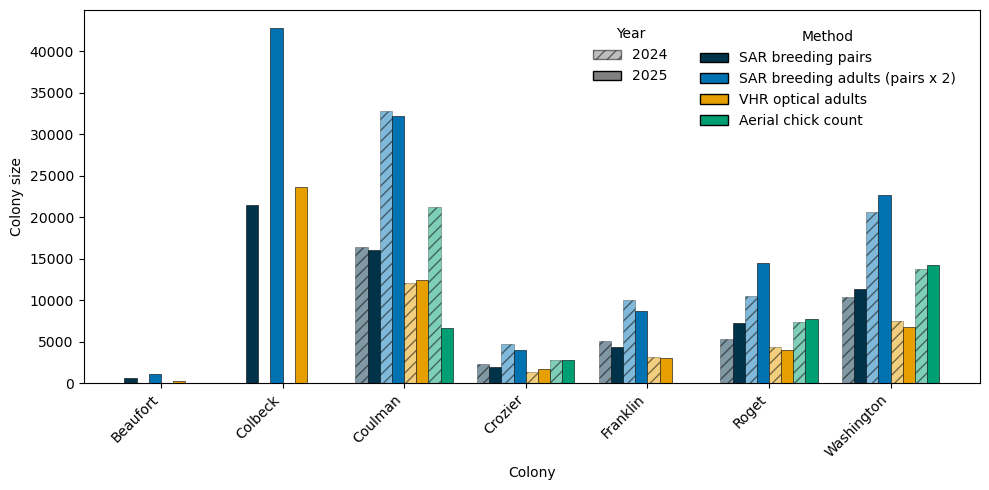

In [76]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# column name: (legend label, colour)
methods = {
    "sar-bp_count": ("SAR breeding pairs","#003349"),
    "breeding_adults": ("SAR breeding adults (pairs x 2)", "#0072B2"),
    "vhr-bayes_count": ("VHR optical adults", "#E69F00"),
    "chick_count": ("Aerial chick count", "#009E73"),
}

def plot_by_year(df, log_scale=False, outfile="colony_sizes.png"):
    colonies = sorted(df["colony"].unique())
    years = sorted(df["year"].unique())
    first_year = years[0]

    x = np.arange(len(colonies))              # one position per colony
    n_bars = len(methods) * len(years)        # 3 methods x 2 years = 6 bars
    width = 0.8 / n_bars

    fig, ax = plt.subplots(figsize=(10, 5))
    bar_number = 0
    for col, (label, colour) in methods.items():
        for yr in years:
            # this year's value for each colony (NaN if missing)
            values = (df[df["year"] == yr]
                      .set_index("colony")[col]
                      .reindex(colonies))
            # first year hatched lighter, second year solid
            if yr == first_year:
                alpha, hatch = 0.5, "///"
            else:
                alpha, hatch =  1.0, ""
            offset = (bar_number - (n_bars - 1) / 2) * width
            ax.bar(x + offset, values, width=width, color=colour,
                   alpha=alpha, hatch=hatch, edgecolor="black", linewidth=0.4)
            bar_number += 1

    ax.set_xticks(x)
    ax.set_xticklabels(colonies, rotation=45, ha="right")
    ax.set_xlabel("Colony")
    if log_scale:
        ax.set_yscale("log")
        ax.set_ylabel("Colony size (log scale)")
    else:
        ax.set_ylabel("Colony size")

    # two legends: colour = method, hatching = year
    method_key = [Patch(facecolor=c, edgecolor="black", label=l)
                  for l, c in methods.values()]
    year_key = [Patch(facecolor="grey", edgecolor="black", alpha=0.5,
                      hatch="///", label=str(years[0])),
                      Patch(facecolor="grey", edgecolor="black", label=str(years[1]))
                ]
    leg1 = ax.legend(handles=method_key, title="Method", ncol=1,
                     loc="lower center", bbox_to_anchor=(0.83, 0.65), frameon=False)
    ax.add_artist(leg1)
    leg2 = ax.legend(handles=year_key, title="Year", loc="lower center",
                     bbox_to_anchor=(0.61, 0.77), frameon=False)

    fig.tight_layout()
    fig.savefig(outfile, dpi=600, bbox_inches="tight",
                bbox_extra_artists=[leg1, leg2])
    plt.show()

from pathlib import Path
results_dir = Path(INPUTPATH) / "Results"

# raw counts, then log scale
plot_by_year(combined_2, log_scale=False, outfile= results_dir / "colony_sizes_raw.png")

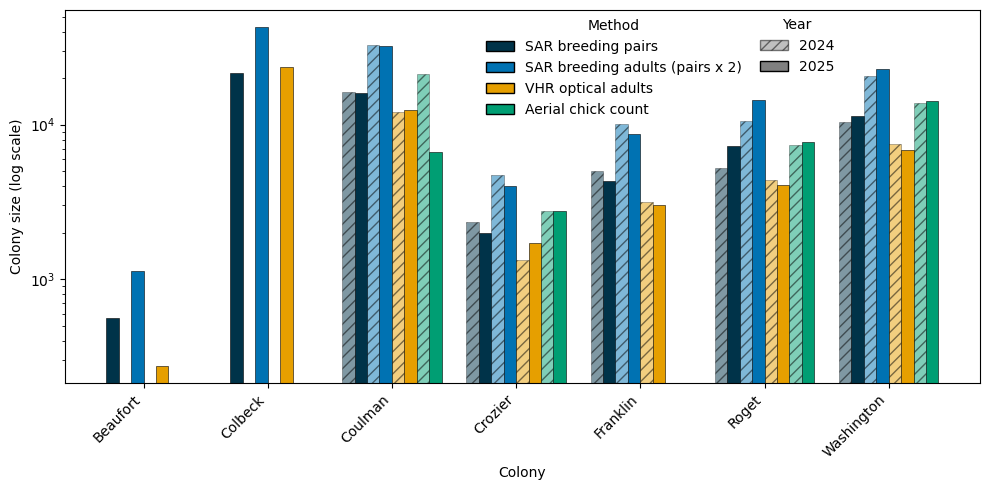

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# column name: (legend label, colour)
methods = {
    "sar-bp_count": ("SAR breeding pairs","#003349"),
    "breeding_adults": ("SAR breeding adults (pairs x 2)", "#0072B2"),
    "vhr-bayes_count": ("VHR optical adults", "#E69F00"),
    "chick_count": ("Aerial chick count", "#009E73"),
}

def plot_by_year(df, log_scale=False, outfile="colony_sizes.png"):
    colonies = sorted(df["colony"].unique())
    years = sorted(df["year"].unique())
    first_year = years[0]

    x = np.arange(len(colonies))              # one position per colony
    n_bars = len(methods) * len(years)        # 3 methods x 2 years = 6 bars
    width = 0.8 / n_bars

    fig, ax = plt.subplots(figsize=(10, 5))
    bar_number = 0
    for col, (label, colour) in methods.items():
        for yr in years:
            # this year's value for each colony (NaN if missing)
            values = (df[df["year"] == yr]
                      .set_index("colony")[col]
                      .reindex(colonies))
            # first year hatched lighter, second year solid
            if yr == first_year:
                alpha, hatch = 0.5, "///"
            else:
                alpha, hatch =  1.0, ""
            offset = (bar_number - (n_bars - 1) / 2) * width
            ax.bar(x + offset, values, width=width, color=colour,
                   alpha=alpha, hatch=hatch, edgecolor="black", linewidth=0.4)
            bar_number += 1

    ax.set_xticks(x)
    ax.set_xticklabels(colonies, rotation=45, ha="right")
    ax.set_xlabel("Colony")
    if log_scale:
        ax.set_yscale("log")
        ax.set_ylabel("Colony size (log scale)")
    else:
        ax.set_ylabel("Colony size")

    # two legends: colour = method, hatching = year
    method_key = [Patch(facecolor=c, edgecolor="black", label=l)
                  for l, c in methods.values()]
    year_key = [Patch(facecolor="grey", edgecolor="black", alpha=0.5,
                      hatch="///", label=str(years[0])),
                      Patch(facecolor="grey", edgecolor="black", label=str(years[1]))
                ]
    leg1 = ax.legend(handles=method_key, title="Method", ncol=1,
                     loc="lower center", bbox_to_anchor=(0.6, 0.68), frameon=False)
    ax.add_artist(leg1)
    leg2 = ax.legend(handles=year_key, title="Year", loc="lower center",
                     bbox_to_anchor=(0.8, 0.795), frameon=False)

    fig.tight_layout()
    fig.savefig(outfile, dpi=600, bbox_inches="tight",
                bbox_extra_artists=[leg1, leg2])
    plt.show()

from pathlib import Path
results_dir = Path(INPUTPATH) / "Results"

#  log scale
plot_by_year(combined_2, log_scale=True, outfile= results_dir / "colony_sizes_log.png")

In [109]:
#Now I want to assess relationships between variables 

RANDOM_SEED = 2026

import numpy as np
import pandas as pd
from pathlib import Path
from itertools import combinations
from scipy import stats
import pymc as pm
import arviz as az


# ---------------------------------------------------------------------------
# Simple, assumption-safe check: average each colony across years,
#     then correlate on the log scale (one independent point per colony)
# ---------------------------------------------------------------------------

# log of each count (missing chick counts stay missing)
combined_2["log_sar"] = np.log(combined_2["breeding_adults"])
combined_2["log_vhr"] = np.log(combined_2["vhr-bayes_count"])
combined_2["log_chick"] = np.log(combined_2["chick_count"])

log_cols = ["log_sar", "log_vhr", "log_chick"]
print(combined_2)

/home/rfo37/miniconda3/envs/era5_env/lib/python3.14/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


        colony  year  sar-bp_count  chick_count  vhr-bayes_count  \
0     Beaufort  2025        563.95          NaN        273.90000   
1      Colbeck  2025      21418.41          NaN      23618.61000   
2      Coulman  2025      16088.12       6686.0      12409.81000   
3      Coulman  2024      16376.19      21242.0      12045.81618   
4      Crozier  2025       1990.66       2782.0       1715.35000   
5      Crozier  2024       2349.79       2773.0       1332.22000   
6     Franklin  2025       4318.43          NaN       2998.27000   
7     Franklin  2024       5029.93          NaN       3172.53000   
8        Roget  2025       7252.01       7736.0       4049.60000   
9        Roget  2024       5261.45       7397.0       4382.11000   
10  Washington  2025      11367.90      14297.0       6819.64000   
11  Washington  2024      10341.24      13803.0       7458.19000   

    breeding_adults    log_sar    log_vhr  log_chick  
0           1127.90   7.028113   5.612763        NaN  
1    

In [110]:
colony_means = combined_2.groupby("colony")[log_cols].mean()

results = []
for a, b in combinations(log_cols, 2):        # all three pairs, generated for you
    pair = colony_means[[a, b]].dropna()       # colonies with both methods
    pearson = stats.pearsonr(pair[a], pair[b])
    ci = pearson.confidence_interval()
    rho, p_rho = stats.spearmanr(pair[a], pair[b])
    results.append({
        "pair": f"{a} vs {b}",
        "n_colonies": len(pair),
        "pearson_r": pearson.statistic,
        "ci_low": ci.low, "ci_high": ci.high,
        "p": pearson.pvalue,
        "spearman_rho": rho, "p_spearman": p_rho,
    })

print(pd.DataFrame(results).round(3))

                   pair  n_colonies  pearson_r  ci_low  ci_high      p  \
0    log_sar vs log_vhr           7      0.995   0.968    0.999  0.000   
1  log_sar vs log_chick           4      0.958  -0.043    0.999  0.042   
2  log_vhr vs log_chick           4      0.938  -0.235    0.999  0.062   

   spearman_rho  p_spearman  
0           1.0         0.0  
1           0.8         0.2  
2           0.8         0.2  


In [111]:
print(colony_means)

              log_sar    log_vhr  log_chick
colony                                     
Beaufort     7.028113   5.612763        NaN
Colbeck     10.665153  10.069790        NaN
Coulman     10.387857   9.411358   9.385753
Crozier      8.372299   7.320987   7.929305
Franklin     9.140051   8.034038        NaN
Roget        9.421745   8.345830   8.931235
Washington   9.984369   8.872315   9.550223


In [ ]:
def colony_averaged_correlations(df):
    means = df.groupby("colony")[log_cols].mean()  # skips NA
    rows = []
    for a, b in combinations (log_cols, 2):
        sub = means[[a, b]].dropna()
        n = len(sub)
        if n < 3:
            rows.append(dict(pair=f"{a} vs {b}", n_colonies=n))
            continue
        r, p = stats.pearsonr(sub[a], sub[b])
        rho, p_rho = stats.spearmanr(sub[a], sub[b])
        # Fisher z 95% CI (needs n >= 4)
        if n >= 4:
            z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
            lo, hi = np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)
        else:
            lo = hi = np.nan
        rows.append(dict(pair=f"{a} vs {b}", n_colonies=n,
                         pearson_r=r, ci_low=lo, ci_high=hi, p=p,
                         spearman_rho=rho, p_spearman=p_rho))
    return pd.DataFrame(rows)


def summarise_correlations(idata, prior):
    post = idata.posterior["colony_corr"]
    prior = prior.prior["colony_corr"]
    rows = []
    for a, b in combinations(log_cos,2):
        d = post.sel(method_1=a, method_2=b).values.ravel()
        p = prior.sel(method_1=a, method_2=b).values.ravel()
        lo, hi = np.percentile(d, [2.5, 97.5])
        p_lo, p_hi = np.percentile(p, [2.5, 97.5])
        rows.append(dict(pair=f"{a} vs {b}",
                         posterior_median=np.median(d),
                         ci95_low=lo, ci95_high=hi,
                         prob_positive=(d > 0).mean(),
                         prior_ci95_width=p_hi - p_lo,
                         posterior_ci95_width=hi - lo))
    return pd.DataFrame(rows)

print("\nColony-averaged correlations (log scale, one point per colony)")
print(colony_averaged_correlations(combined_2).round(3).to_string(index=False))


In [122]:
# log ratio per colony, averaged across years (one value per colony)
combined_2["lr_vhr_sar"] = combined_2["log_vhr"] - combined_2["log_sar"]
combined_2["lr_chick_pair"] = np.log(combined_2["chick_count"] / combined_2["sar-bp_count"])

for col, name in [("lr_vhr_sar", "VHR adults per SAR breeding adult"),
                  ("lr_chick_pair", "Chicks per SAR breeding pair")]:
    per_colony = combined_2.groupby("colony")[col].mean().dropna()
    n = len(per_colony)
    m, sd = per_colony.mean(), per_colony.std(ddof=1)
    t = stats.t.ppf(0.975, n - 1)
    print(f"\n{name} (n = {n} colonies)")
    print(f"  mean ratio: {np.exp(m):.3f}  "
          f"(95% CI {np.exp(m - t * sd / np.sqrt(n)):.3f} to {np.exp(m + t * sd / np.sqrt(n)):.3f})")
    print(f"  limits of agreement: {np.exp(m - 1.96 * sd):.3f} to {np.exp(m + 1.96 * sd):.3f}")


VHR adults per SAR breeding adult (n = 7 colonies)
  mean ratio: 0.351  (95% CI 0.280 to 0.439)
  limits of agreement: 0.218 to 0.564

Chicks per SAR breeding pair (n = 4 colonies)
  mean ratio: 1.106  (95% CI 0.715 to 1.711)
  limits of agreement: 0.646 to 1.893
